# Playlist Detective 1: Copycat Playlists
### MATH 3280 · Similarities: Minhashing and Locality-Sensitive Hashing

A small music-streaming startup, **Tunebasket**, has 1,000 user playlists. Each playlist is just a *set of artists*.

Some users copy someone else's playlist and change a few artists. Tunebasket wants every pair of playlists with Jaccard similarity **at least 0.6**, but without comparing all ~500,000 pairs. You will build the tools to do that: minhash signatures to shrink each playlist, then LSH to find the few pairs worth checking.

**Rules**

* Implement Jaccard similarity, minhashing, and LSH banding **yourself**.

* Use only `numpy`, `pandas`, `matplotlib`, `itertools`, `collections`, and `time`. You may use a library such as `mlxtend` or `datasketch` *only* to double-check your answers, and you must say so if you do.
* Every cell marked `# TODO` needs code. Every "**Your answer**" cell needs a few sentences.
* Run the whole notebook top to bottom (*Kernel → Restart & Run All*) before you submit.

All artist names are fictional.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter, defaultdict
import time

SEED = 3280
rng = np.random.default_rng(SEED)

## Part 0 · Load and explore the data (10 pts)

`playlists.csv` has one row per (playlist, artist). Build:

* `baskets`: a dictionary `playlist_id -> {set of artists}`
* `artists`: a sorted list of all artists, and `artist_index`: a dictionary `artist -> row number`
* `playlist_ids`: a sorted list of playlist ids
* `M`: the characteristic (utility) matrix, a 0/1 NumPy array with one row per artist and one column per playlist, so `M[i, j] = 1` when artist `i` is in playlist `j`.

In [15]:
df = pd.read_csv("playlists.csv")

# Go through the CSV row by row and add each artist to its playlist's set
baskets = {}
for p, a in zip(df["playlist_id"], df["artist"]):
    if p not in baskets:
        baskets[p] = set()        # first time seeing this playlist: start an empty set
    baskets[p].add(a)

playlist_ids = sorted(baskets.keys())



artists = sorted(set(df["artist"]))

# Give each artist a row number: 0, 1, 2, ...
artist_index = {}
for i, a in enumerate(artists):
    artist_index[a] = i

# Start with all zeros, then put a 1 wherever an artist is in a playlist
M = np.zeros((len(artists), len(playlist_ids)), dtype=int)
for j, p in enumerate(playlist_ids):
    for a in baskets[p]:
        i = artist_index[a]
        M[i, j] = 1

print("playlists:", len(playlist_ids), " artists:", len(artists), " M shape:", M.shape)


playlists: 1000  artists: 481  M shape: (481, 1000)


In [16]:
# Quick look: playlist sizes and the most common artists
sizes = pd.Series({p: len(s) for p, s in baskets.items()})
print(sizes.describe())
print(df["artist"].value_counts().head(10))

count    1000.000000
mean       16.814000
std         4.486818
min         8.000000
25%        13.000000
50%        17.000000
75%        20.000000
max        29.000000
dtype: float64
artist
Nova Lux                463
The Glass Meadow        158
The Paper Rivers        138
The Electric Circuit    135
The Neon Rivers         131
The Midnight Orchard    122
The Thunder Wolves      119
The Frozen Comets       114
The Wild Comets         107
The Electric Foxes      105
Name: count, dtype: int64


**Q0.** How many of the $\binom{1000}{2}$ pairs of playlists would a brute-force search compare? What fraction of the matrix `M` is 1s? Why does that sparsity matter for how real systems store this matrix?

**Your answer:** 

We've 1,000 playlists in total and 481 rows of artists. Using combinations formula for combination of 2 Ns of 100 length, we get n(n-1)/2 which results in 1000(999)/2 = 499,500. So, a brute-force search would need 499,500 comparisions. The characteristic matrix M contains 481 rows and 1,000 columns which is a total of 481,000 entries in total. Since there are 16,814 amount of artist-playlist, only about 3.5% ((16.814 * 1000) / (481 * 1000)) of the matrix entries are 1s, and the remaining 96.50% are 0s. 

Talking about sparsity, the above data shows that the matrix is sparsed. In a real system, storing the full matrix on memory might waste a lot of memory in the zeros. Instead we could use a sparse matrix representation that would significantly reduce memory usage and make it easier to handle larger datasets. 

## Part 1 · Warm-up: Jaccard similarity and the S-curve (15 pts)

Write three small functions, then check them with the `assert` cell.

* `jaccard(A, B)` $= |A \cap B| / |A \cup B|$
* `candidate_prob(s, b, r)` $= 1 - (1 - s^r)^b$, the probability that two sets with similarity $s$ become an LSH candidate pair with $b$ bands of $r$ rows
* `lsh_threshold(b, r)` $\approx (1/b)^{1/r}$, the similarity where the S-curve rises most steeply

In [4]:
def jaccard(A, B):
    # |A ∩ B| / |A ∪ B|
    A, B = set(A), set(B)          # so strings like "john" become sets of letters
    union = A | B
    if not union:                  # both sets empty: define similarity as 0
        return 0.0
    return len(A & B) / len(union)

def candidate_prob(s, b, r):
    # 1 - (1 - s^r)^b  (works for a single s or a NumPy array of s values)
    return 1 - (1 - s**r)**b

def lsh_threshold(b, r):
    # (1/b)^(1/r)
    return (1 / b) ** (1 / r)

In [5]:
assert abs(jaccard({1, 2, 3}, {2, 3, 4}) - 0.5) < 1e-9
assert abs(jaccard("john", "joan") - 3/5) < 1e-9          # letters as sets: {j,o,h,n} vs {j,o,a,n}
assert jaccard({1, 2}, {3, 4}) == 0
assert abs(candidate_prob(0.8, 20, 5) - 0.99964) < 1e-4    # the textbook's b = 20, r = 5 example
assert abs(lsh_threshold(20, 5) - 0.5493) < 1e-3
print("Part 1 checks passed.")

Part 1 checks passed.


## Part 2 · Minhashing (30 pts)

Permuting 481 rows hundreds of times is slow, so we simulate each permutation with a hash function

$$h_i(x) = (a_i x + b_i) \bmod p,$$

where $x$ is the row number, $p$ is a prime larger than the number of rows, and $a_i, b_i$ are random integers with $1 \le a_i < p$ and $0 \le b_i < p$.

**2a.** Write `minhash_signatures(M, n_hashes, seed)` that returns the $n \times (\text{\# playlists})$ signature matrix using the row-by-row algorithm from the notes:

1. Start every signature entry at a very large value. For example, $SIG[i, c] = 99999$.
2. For each row $r$: compute $h_1(r), \dots, h_n(r)$. For each column $c$ with $M[r, c] = 1$, replace $SIG[i, c]$ by $\min(SIG[i, c],\, h_i(r))$.

*(Hint: for one row, you can update all of its columns at once with `np.minimum`.)*

In [20]:
P = 4_294_967_311  # a prime larger than 2^32

def make_hashes(n_hashes, seed=SEED):
    g = np.random.default_rng(seed)
    a = g.integers(1, P, size=n_hashes, dtype=np.int64)
    b = g.integers(0, P, size=n_hashes, dtype=np.int64)
    return a, b

def minhash_signatures(M, n_hashes, seed=SEED):
    a, b = make_hashes(n_hashes, seed)
    n_rows, n_cols = M.shape

    # Step 1: start every entry at "infinity". Hash values go up to P (~4.3 billion),
    # so 99999 would be too small; P itself is larger than any hash value.
    SIG = np.full((n_hashes, n_cols), P, dtype=np.int64)

    # Step 2: go through the rows one at a time
    for r in range(n_rows):
        h = (a * r + b) % P              # h_1(r), ..., h_n(r): one value per hash function
        cols = np.nonzero(M[r])[0]       # the columns (playlists) that have a 1 in this row
        if len(cols) == 0:
            continue
        # for those columns, keep the smaller of the current signature and h_i(r)
        SIG[:, cols] = np.minimum(SIG[:, cols], h[:, None])

    return SIG

def estimated_jaccard(SIG, c1, c2):
    # fraction of signature rows where columns c1 and c2 agree
    return np.mean(SIG[:, c1] == SIG[:, c2])

In [21]:
# Checks
SIG = minhash_signatures(M, 100)
assert SIG.shape == (100, len(playlist_ids))
same = minhash_signatures(np.array([[1, 1], [0, 0], [1, 1]]), 50)
assert estimated_jaccard(same, 0, 1) == 1.0          # identical columns always agree
print("Part 2a checks passed.")

Part 2a checks passed.


**2b. How good is the estimate?** Pick 200 random pairs of playlists **plus** the pair `("P0265", "P0473")`. For $n \in \{10, 25, 50, 100, 200, 400\}$ hash functions, compute the mean absolute error between the minhash estimate and the true Jaccard similarity. Plot error vs. $n$.

     n  mean abs error
0   10        0.021561
1   25        0.014667
2   50        0.008640
3  100        0.009627
4  200        0.005400
5  400        0.004474
P0265 vs P0473: true J = 0.913


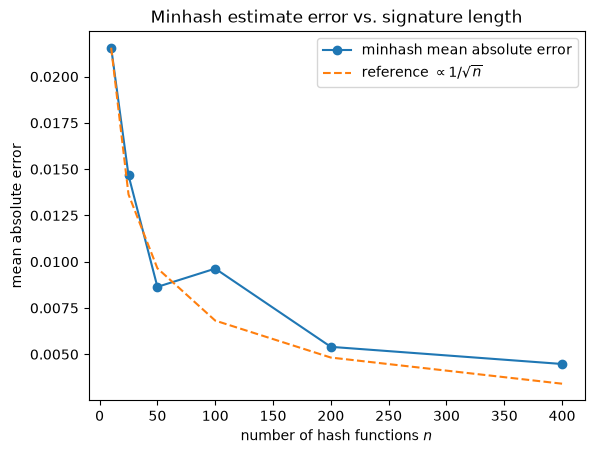

In [22]:
col = {p: j for j, p in enumerate(playlist_ids)}
pair_rng = np.random.default_rng(1)
test_pairs = [tuple(pair_rng.choice(len(playlist_ids), 2, replace=False)) for _ in range(200)]
test_pairs.append((col["P0265"], col["P0473"]))

# True Jaccard for each test pair (computed exactly from the sets)
true_J = np.array([jaccard(baskets[playlist_ids[c1]], baskets[playlist_ids[c2]])
                   for c1, c2 in test_pairs])

# Mean absolute error of the minhash estimate for each number of hash functions
n_values = [10, 25, 50, 100, 200, 400]
mae = []
for n in n_values:
    SIG_n = minhash_signatures(M, n)
    est_J = np.array([estimated_jaccard(SIG_n, c1, c2) for c1, c2 in test_pairs])
    mae.append(np.mean(np.abs(est_J - true_J)))

print(pd.DataFrame({"n": n_values, "mean abs error": mae}))
print("P0265 vs P0473: true J =", round(true_J[-1], 4))

# Plot error vs n, with a c/sqrt(n) reference curve for comparison
plt.plot(n_values, mae, "o-", label="minhash mean absolute error")
plt.plot(n_values, mae[0] * np.sqrt(n_values[0]) / np.sqrt(n_values), "--",
         label=r"reference $\propto 1/\sqrt{n}$")
plt.xlabel("number of hash functions $n$")
plt.ylabel("mean absolute error")
plt.title("Minhash estimate error vs. signature length")
plt.legend()
plt.show()

**Q2.** Each signature row agrees with probability $J$, so the estimate is a sample proportion. Its standard error is $\sqrt{J(1-J)/n}$. Does your plot shrink like $1/\sqrt{n}$? How many hash functions would you need so the standard error is at most 0.05 for a pair with $J = 0.5$?

Yesm  the MAE generally decreases when the number of hash functions increase and the relationship is with 1/(square root of (n)). Based on the result, the error decreased from 0.0216 with 10 hash functions to 0.0045 with 400 hash functions. However, we can see that the decrease is not perfectly smooth. We could also see that there is a slight increase when going from 50 to 100 hashes, which is reasonable since minhashing is simply a process of estimation. 

Finding how many hashes are needed for a standard error of at most 0.05 when j = 0.5, we use SE = $\sqrt{J(1-J)/n}$ 
Solving for n gives, 0.25/n <= 0.0025, meaning n >= 100. Therefore, we would need at least 100 hash functions to meet the required standard error. 

## Part 3 · Locality-Sensitive Hashing (45 pts)

Split the $n = 100$ signature rows into $b$ bands of $r$ rows ($br = 100$). Two playlists become a **candidate pair** if their signatures agree on *every* row of *at least one* band.

**3a.** Using your Part 1 functions, plot the S-curve for every $(b, r)$ with $br = 100$ and $r \in \{2, 4, 5, 10, 20\}$. Mark the target $s = 0.6$. Choose a $(b, r)$ for this job, and justify your choice in terms of false positives and false negatives.

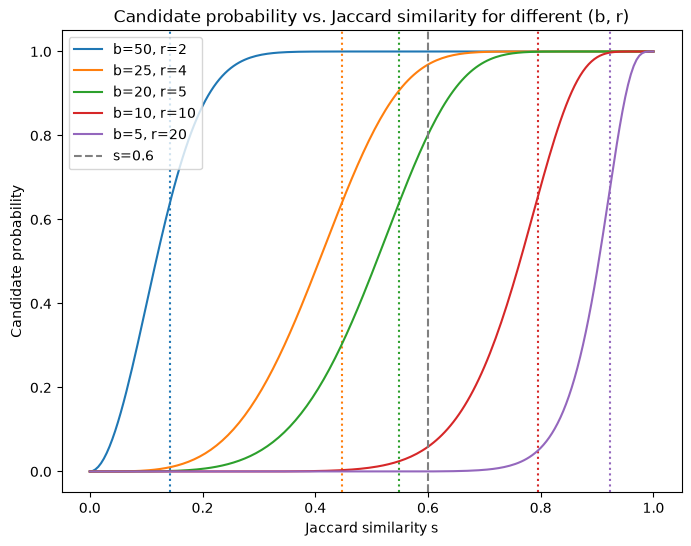

In [9]:
s = np.linspace(0, 1, 201)
plt.figure(figsize=(8, 6))
for b, r in [(50, 2), (25, 4), (20, 5), (10, 10), (5, 20)]:
    line, = plt.plot(s, candidate_prob(s, b, r), label=f"b={b}, r={r}")
    t = lsh_threshold(b, r)
    plt.axvline(t, color=line.get_color(), linestyle=":")
plt.axvline(0.6, color="gray", linestyle="--", label="s=0.6")
plt.xlabel("Jaccard similarity s")
plt.ylabel("Candidate probability")
plt.title("Candidate probability vs. Jaccard similarity for different (b, r)")
plt.legend()

**Your answer:** *I'm leaning more towards the b=20 r=5 cut, because based on the figure, this provides a good balance between false positives and false negatives. The threshold line appears around a 80% probability that they will be a candidate pair, whereas the b=10 and r=10 the threshold appears with <10% probability of it being a candidate pair. So if I chose that option there is a greater potential to have false negatives*

**3b.** Write `lsh_candidates(SIG, b, r)`. For each band, use the tuple of that band's $r$ values as a bucket key (a dictionary is a hash table). Every pair of columns that share a bucket in any band is a candidate. Return a **set** of `(i, j)` pairs with `i < j`.

In [10]:
def lsh_candidates(SIG, b, r):
    assert SIG.shape[0] == b * r
    cands = set()
    # TODO: for each band, bucket the columns by their band values; add all pairs in a shared bucket
    for band_index in range(b):
        band = SIG[band_index*r:(band_index+1)*r, :] # gets the rows for the current band with all columns
        buckets = {}
        for column_index in range(band.shape[1]): # iterate over each column (playlist)
            band_tuple = tuple(band[:, column_index]) # convert the band values (signatures of band) to a tuple to use as a key
            if band_tuple not in buckets:
                buckets[band_tuple] = []
            buckets[band_tuple].append(column_index) # add the column index to the corresponding bucket
        for bucket in buckets.values():
            if len(bucket) > 1:
                for pair in combinations(bucket, 2):
                    cands.add(tuple(sorted(pair))) # add the pair as a sorted tuple to avoid duplicates
        
    return cands

**3c. Does it work?** Using your $(b, r)$:

1. Time the LSH step and the follow-up step that keeps candidates whose **exact** Jaccard is $\ge 0.6$.
2. Time a brute-force search over all pairs for the true answer.
3. Report the number of candidates, true positives, false positives (candidates with $J < 0.6$), and false negatives (true pairs LSH missed).

In [11]:
THRESH = 0.6
B_orig, R_orig = 20, 5   # Your choice from 3a
sets = [baskets[p] for p in playlist_ids]

# time (minhash + LSH + exact check of candidates)
start_time = time.time()
SIG_orig = minhash_signatures(M, B_orig * R_orig)
cands_orig = lsh_candidates(SIG_orig, B_orig, R_orig)
true_positives_orig = set()
for c1, c2 in cands_orig:
    if jaccard(sets[c1], sets[c2]) >= THRESH:
        true_positives_orig.add((c1, c2))
end_time = time.time()
duration_lsh_orig = end_time - start_time
print(f"LSH time: {end_time - start_time:.2f} seconds")

# time a brute-force search over all pairs
start_time = time.time()
true_pairs_orig = set()
for c1, c2 in combinations(range(len(playlist_ids)), 2):
    if jaccard(sets[c1], sets[c2]) >= THRESH:
        true_pairs_orig.add((c1, c2))
end_time = time.time()
duration_brute_orig = end_time - start_time
print(f"Brute-force time: {end_time - start_time:.2f} seconds")

# report candidates, true positives, false positives, false negatives; list the pairs you found
print(f"LSH candidates: {len(cands_orig)}")
print(f"True positives: {len(true_positives_orig)}")
print(f"True pairs (brute-force): {len(true_pairs_orig)}")
false_positives_orig = cands_orig - true_pairs_orig
false_negatives_orig = true_pairs_orig - cands_orig
print(f"False positives: {len(false_positives_orig)}")
print(f"False negatives: {len(false_negatives_orig)}")
for c1, c2 in sorted(true_positives_orig):
    print(f"True positive: {playlist_ids[c1]} and {playlist_ids[c2]}, Jaccard: {jaccard(sets[c1], sets[c2]):.4f}")
for c1, c2 in sorted(false_positives_orig):
    print(f"False positive: {playlist_ids[c1]} and {playlist_ids[c2]}, Jaccard: {jaccard(sets[c1], sets[c2]):.4f}")

LSH time: 0.04 seconds
Brute-force time: 1.37 seconds
LSH candidates: 562
True positives: 18
True pairs (brute-force): 20
False positives: 544
False negatives: 2
True positive: P0015 and P0335, Jaccard: 0.6842
True positive: P0030 and P0814, Jaccard: 0.6842
True positive: P0048 and P0190, Jaccard: 0.9130
True positive: P0051 and P0988, Jaccard: 0.7333
True positive: P0074 and P0484, Jaccard: 0.7391
True positive: P0110 and P0659, Jaccard: 0.6800
True positive: P0265 and P0473, Jaccard: 0.9130
True positive: P0287 and P0968, Jaccard: 0.8947
True positive: P0304 and P0748, Jaccard: 0.6471
True positive: P0328 and P0701, Jaccard: 0.7895
True positive: P0339 and P0343, Jaccard: 0.6800
True positive: P0426 and P0933, Jaccard: 0.6522
True positive: P0519 and P0649, Jaccard: 0.7500
True positive: P0537 and P0739, Jaccard: 0.6800
True positive: P0635 and P0871, Jaccard: 0.9048
True positive: P0725 and P0843, Jaccard: 0.7895
True positive: P0813 and P0899, Jaccard: 0.7600
True positive: P0888 a

**3d.** Repeat 3c for two other $(b, r)$ choices, one with a higher threshold and one with a lower threshold. Put the results in a small table (`pd.DataFrame`).

In [12]:
# TODO: build a table comparing (b, r) choices
# Lower threshold
THRESH = 0.6
B_low, R_low = 25, 4
sets = [baskets[p] for p in playlist_ids]

print(f"Lower threshold: B={B_low}, R={R_low}, threshold={lsh_threshold(B_low, R_low):.4f}")

# time (minhash + LSH + exact check of candidates)
start_time = time.time()
SIG_low = minhash_signatures(M, B_low * R_low)
cands_low = lsh_candidates(SIG_low, B_low, R_low)
true_positives_low = set()
for c1, c2 in cands_low:
    if jaccard(sets[c1], sets[c2]) >= THRESH:
        true_positives_low.add((c1, c2))
end_time = time.time()
duration_lsh_low = end_time - start_time
print(f"LSH time: {end_time - start_time:.2f} seconds")

# time a brute-force search over all pairs
start_time = time.time()
true_pairs_low = set()
for c1, c2 in combinations(range(len(playlist_ids)), 2):
    if jaccard(sets[c1], sets[c2]) >= THRESH:
        true_pairs_low.add((c1, c2))
end_time = time.time()
duration_brute_low = end_time - start_time
print(f"Brute-force time: {end_time - start_time:.2f} seconds")

# report candidates, true positives, false positives, false negatives; list the pairs you found
print(f"LSH candidates: {len(cands_low)}")
print(f"True positives: {len(true_positives_low)}")
print(f"True pairs (brute-force): {len(true_pairs_low)}")
false_positives_low = cands_low - true_pairs_low
false_negatives_low = true_pairs_low - cands_low
print(f"False positives: {len(false_positives_low)}")
print(f"False negatives: {len(false_negatives_low)}")
for c1, c2 in sorted(true_positives_low):
    print(f"True positive: {playlist_ids[c1]} and {playlist_ids[c2]}, Jaccard: {jaccard(sets[c1], sets[c2]):.4f}")
for c1, c2 in sorted(false_positives_low):
    print(f"False positive: {playlist_ids[c1]} and {playlist_ids[c2]}, Jaccard: {jaccard(sets[c1], sets[c2]):.4f}")


THRESH = 0.6
B_high, R_high = 10, 10

print(f"\nHigher threshold: B={B_high}, R={R_high}, threshold={lsh_threshold(B_high, R_high):.4f}")

sets = [baskets[p] for p in playlist_ids]

# time (minhash + LSH + exact check of candidates)
start_time = time.time()
SIG_high = minhash_signatures(M, B_high * R_high)
cands_high = lsh_candidates(SIG_high, B_high, R_high)
true_positives_high = set()
for c1, c2 in cands_high:
    if jaccard(sets[c1], sets[c2]) >= THRESH:
        true_positives_high.add((c1, c2))
end_time = time.time()
duration_lsh_high = end_time - start_time
print(f"LSH time: {end_time - start_time:.2f} seconds")

# time a brute-force search over all pairs
start_time = time.time()
true_pairs_high = set()
for c1, c2 in combinations(range(len(playlist_ids)), 2):
    if jaccard(sets[c1], sets[c2]) >= THRESH:
        true_pairs_high.add((c1, c2))
end_time = time.time()
duration_brute_high = end_time - start_time
print(f"Brute-force time: {end_time - start_time:.2f} seconds")

# report candidates, true positives, false positives, false negatives; list the pairs you found
print(f"LSH candidates: {len(cands_high)}")
print(f"True positives: {len(true_positives_high)}")
print(f"True pairs (brute-force): {len(true_pairs_high)}")
false_positives_high = cands_high - true_pairs_high
false_negatives_high = true_pairs_high - cands_high
print(f"False positives: {len(false_positives_high)}")
print(f"False negatives: {len(false_negatives_high)}")
for c1, c2 in sorted(true_positives_high):
    print(f"True positive: {playlist_ids[c1]} and {playlist_ids[c2]}, Jaccard: {jaccard(sets[c1], sets[c2]):.4f}")
for c1, c2 in sorted(false_positives_high):
    print(f"False positive: {playlist_ids[c1]} and {playlist_ids[c2]}, Jaccard: {jaccard(sets[c1], sets[c2]):.4f}")

results = pd.DataFrame({
    "B": [20, 25, 10],
    "R": [5, 4, 10],
    "LSH_Candidates": [len(cands_orig), len(cands_low), len(cands_high)],
    "True_Positives": [len(true_positives_orig), len(true_positives_low), len(true_positives_high)],
    "True_Pairs": [len(true_pairs_orig), len(true_pairs_low), len(true_pairs_high)],
    "False_Positives": [len(false_positives_orig), len(false_positives_low), len(false_positives_high)],
    "False_Negatives": [len(false_negatives_orig), len(false_negatives_low), len(false_negatives_high)],
    "Runtime LSH": [duration_lsh_orig, duration_lsh_low, duration_lsh_high],
    "Runtime Brute": [duration_brute_orig, duration_brute_low, duration_brute_high]
})

display(results)

Lower threshold: B=25, R=4, threshold=0.4472
LSH time: 0.07 seconds
Brute-force time: 1.39 seconds
LSH candidates: 2863
True positives: 19
True pairs (brute-force): 20
False positives: 2844
False negatives: 1
True positive: P0015 and P0335, Jaccard: 0.6842
True positive: P0030 and P0814, Jaccard: 0.6842
True positive: P0043 and P0530, Jaccard: 0.6522
True positive: P0048 and P0190, Jaccard: 0.9130
True positive: P0051 and P0988, Jaccard: 0.7333
True positive: P0074 and P0484, Jaccard: 0.7391
True positive: P0110 and P0659, Jaccard: 0.6800
True positive: P0265 and P0473, Jaccard: 0.9130
True positive: P0287 and P0968, Jaccard: 0.8947
True positive: P0304 and P0748, Jaccard: 0.6471
True positive: P0328 and P0701, Jaccard: 0.7895
True positive: P0339 and P0343, Jaccard: 0.6800
True positive: P0426 and P0933, Jaccard: 0.6522
True positive: P0519 and P0649, Jaccard: 0.7500
True positive: P0537 and P0739, Jaccard: 0.6800
True positive: P0635 and P0871, Jaccard: 0.9048
True positive: P0725 an

,B,R,LSH_Candidates,True_Positives,True_Pairs,False_Positives,False_Negatives,Runtime LSH,Runtime Brute
0,20,5,562,18,20,544,2,0.044800,1.365106
1,25,4,2863,19,20,2844,1,0.068144,1.392419
2,10,10,10,10,20,0,10,0.026902,1.445207


**Q3.** Explain the trade-off you see in your table. In a real system with 100 million playlists, why is a false positive much cheaper than a false negative here?

**Your answer:** *In a false positive you can still check to see if it is a true positive, in a false negative that option just gets skipped there is no check to verify if you missed something. This is shown in the table where with B=25 R=4 there were 2,863 candidate pairs and 2,844 of them were false positives but it was still able to get 19/20 of the true pairs. Compare that to B=10 R=10, where there were only 10 candidates and there were 0 false positives and 10 false negatives. That means it only caught 10/20 of the true pairs. With a huge amount of data like 100 million, it is better to optimize where you have a low amount of false negatives since there is no check on them, but you also don't want to approach a brute force approach where you are checking more candidate pairs than you need to*

We didn't use any library to check any answers. 

## Submission checklist

* [ ] Notebook runs top to bottom with no errors
* [ ] All `assert` checks pass
* [ ] Every **Your answer** cell is filled in
* [ ] Plots have axis labels
* [ ] Any library used to double-check answers is named and discussed